In [40]:
import numpy as np
import matplotlib.pyplot as plt

In [41]:
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5 # Generate 100 random numbers between -0.5 and 0.5
y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)

In [42]:
import pandas as pd

In [43]:
df = pd.DataFrame()

In [44]:
df['X'] = X.reshape(100)
df['y'] = y

In [45]:
df

,X,y
0,-0.125460,0.051573
1,0.450714,0.594480
2,0.231994,0.166052
3,0.098658,-0.070178
4,-0.343981,0.343986
...,...,...
95,-0.006204,-0.040675
96,0.022733,-0.002305
97,-0.072459,0.032809
98,-0.474581,0.689516


Text(0.5, 1.0, 'X vs Y')

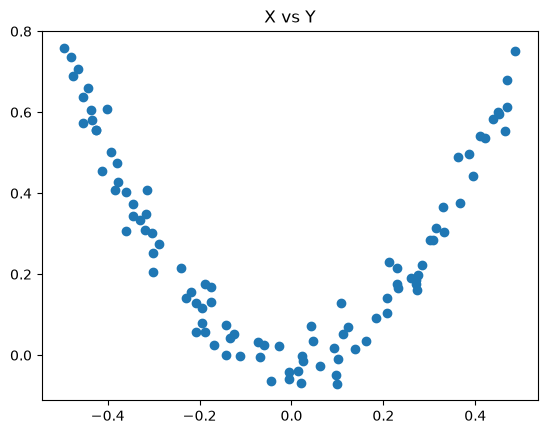

In [46]:
plt.scatter(df['X'],df['y'])
plt.title('X vs Y')

### First model will predict mean of the target variable, and the residuals will be calculated as the difference between the actual target values and the predicted mean values.

In [47]:
df['pred1'] = df['y'].mean()

In [48]:
df

,X,y,pred1
0,-0.125460,0.051573,0.265458
1,0.450714,0.594480,0.265458
2,0.231994,0.166052,0.265458
3,0.098658,-0.070178,0.265458
4,-0.343981,0.343986,0.265458
...,...,...,...
95,-0.006204,-0.040675,0.265458
96,0.022733,-0.002305,0.265458
97,-0.072459,0.032809,0.265458
98,-0.474581,0.689516,0.265458


In [49]:
df['res1'] = df['y'] - df['pred1']

In [50]:
df

,X,y,pred1,res1
0,-0.125460,0.051573,0.265458,-0.213885
1,0.450714,0.594480,0.265458,0.329021
2,0.231994,0.166052,0.265458,-0.099407
3,0.098658,-0.070178,0.265458,-0.335636
4,-0.343981,0.343986,0.265458,0.078528
...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133
96,0.022733,-0.002305,0.265458,-0.267763
97,-0.072459,0.032809,0.265458,-0.232650
98,-0.474581,0.689516,0.265458,0.424057


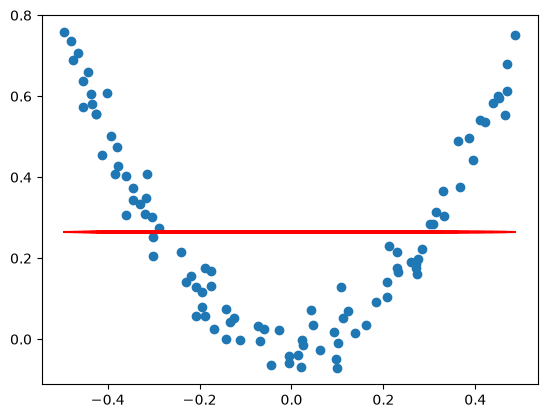

In [51]:
plt.scatter(df['X'],df['y'])
plt.plot(df['X'],df['pred1'],color='red')

### Now train the second model on the residuals and the input features. The second model will predict the residuals, and the new residuals will be calculated as the difference between the actual target values and the predicted values from both the first and second models.

In [52]:
from sklearn.tree import DecisionTreeRegressor

In [53]:
tree1 = DecisionTreeRegressor(max_leaf_nodes=8)

In [54]:
# train 2nd model on the residuals and the input features. The second model will predict the residuals
tree1.fit(df['X'].values.reshape(-1, 1), df['res1'].values)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max

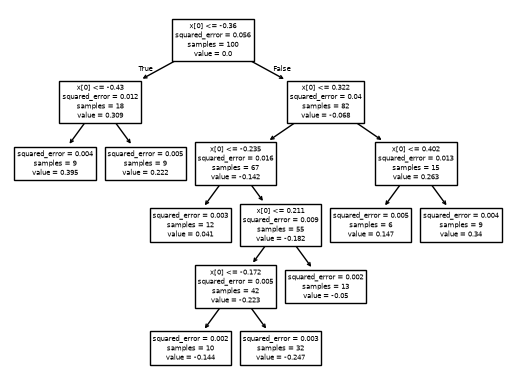

In [55]:
from sklearn.tree import plot_tree
plot_tree(tree1)
plt.show()

In [56]:
# generating X_test
X_test = np.linspace(-0.5, 0.5, 100) # Generate 100 points between -0.5 and 0.5

In [57]:
# predict on the training inputs so rows stay aligned with df (X_test is only for plotting)
df['pred2'] = tree1.predict(df['X'].values.reshape(-1, 1))

In [58]:
df

,X,y,pred1,res1,pred2
0,-0.125460,0.051573,0.265458,-0.213885,-0.247139
1,0.450714,0.594480,0.265458,0.329021,0.340426
2,0.231994,0.166052,0.265458,-0.099407,-0.049674
3,0.098658,-0.070178,0.265458,-0.335636,-0.247139
4,-0.343981,0.343986,0.265458,0.078528,0.040506
...,...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133,-0.247139
96,0.022733,-0.002305,0.265458,-0.267763,-0.247139
97,-0.072459,0.032809,0.265458,-0.232650,-0.247139
98,-0.474581,0.689516,0.265458,0.424057,0.395454


In [59]:
y_pred = df['y'].mean() + tree1.predict(X_test.reshape(-1, 1))

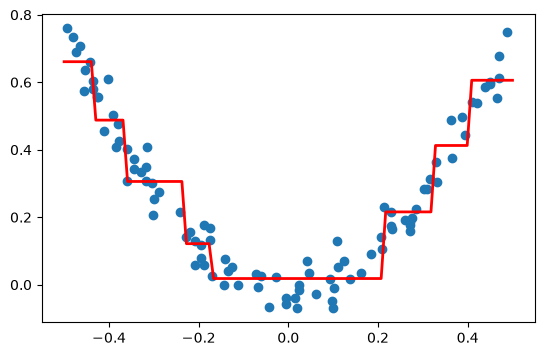

In [60]:
plt.figure(figsize=(14,4))
plt.subplot(121)
plt.plot(X_test, y_pred, linewidth=2,color='red')
plt.scatter(df['X'],df['y'])

- Predicting the target variable using both model:

$$y\_pred = \text{mean\_target} + \text{model2.predict(X\_test)}$$

In [61]:
df['y_pred_2'] = df['pred1'] + df['pred2']

In [62]:
df

,X,y,pred1,res1,pred2,y_pred_2
0,-0.125460,0.051573,0.265458,-0.213885,-0.247139,0.018320
1,0.450714,0.594480,0.265458,0.329021,0.340426,0.605884
2,0.231994,0.166052,0.265458,-0.099407,-0.049674,0.215784
3,0.098658,-0.070178,0.265458,-0.335636,-0.247139,0.018320
4,-0.343981,0.343986,0.265458,0.078528,0.040506,0.305965
...,...,...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133,-0.247139,0.018320
96,0.022733,-0.002305,0.265458,-0.267763,-0.247139,0.018320
97,-0.072459,0.032809,0.265458,-0.232650,-0.247139,0.018320
98,-0.474581,0.689516,0.265458,0.424057,0.395454,0.660912


In [63]:
df['res2'] = df['y'] - df['y_pred_2']

In [64]:
df

,X,y,pred1,res1,pred2,y_pred_2,res2
0,-0.125460,0.051573,0.265458,-0.213885,-0.247139,0.018320,0.033253
1,0.450714,0.594480,0.265458,0.329021,0.340426,0.605884,-0.011404
2,0.231994,0.166052,0.265458,-0.099407,-0.049674,0.215784,-0.049732
3,0.098658,-0.070178,0.265458,-0.335636,-0.247139,0.018320,-0.088497
4,-0.343981,0.343986,0.265458,0.078528,0.040506,0.305965,0.038021
...,...,...,...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133,-0.247139,0.018320,-0.058995
96,0.022733,-0.002305,0.265458,-0.267763,-0.247139,0.018320,-0.020624
97,-0.072459,0.032809,0.265458,-0.232650,-0.247139,0.018320,0.014489
98,-0.474581,0.689516,0.265458,0.424057,0.395454,0.660912,0.028603


- Now the third model (2nd Desicion tree) will be trained on res2 and the input features. 

In [65]:
tree2 = DecisionTreeRegressor(max_leaf_nodes=8)

In [66]:
tree2.fit(df['X'].values.reshape(100,1),df['res2'].values)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max

In [ ]:
df['pred3'] = tree2.predict(df['X'].values.reshape(-1, 1)) # predicting the residuals

In [68]:
Xt = X_test.reshape(-1, 1)
y_pred = df['y'].mean() + tree1.predict(Xt) + tree2.predict(Xt)

Text(0.5, 1.0, 'X vs y')

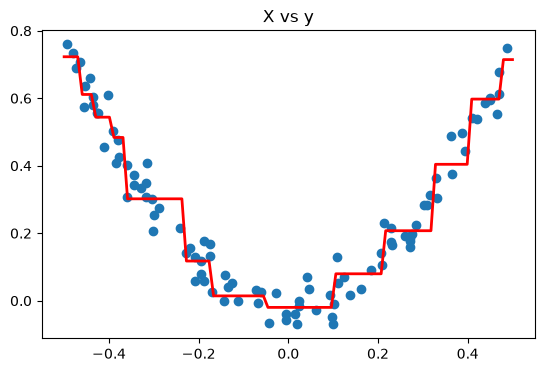

In [69]:
plt.figure(figsize=(14,4))
plt.subplot(121)
plt.plot(X_test, y_pred, linewidth=2,color='red')
plt.scatter(df['X'],df['y'])
plt.title('X vs y')

In [70]:
def gradient_boost(X, y, n_trees, lr):
    regs = []
    pred = np.full(len(y), y.mean(), dtype=float)   # start from the mean
    x1 = np.linspace(-0.5, 0.5, 500).reshape(-1, 1)
    for i in range(1, n_trees + 1):
        res = y - pred                               # residual of the current ensemble
        tree = DecisionTreeRegressor(max_depth=5, random_state=42).fit(X, res)
        regs.append(tree)
        pred += lr * tree.predict(X)

        y_plot = y.mean() + sum(lr * t.predict(x1) for t in regs)
        plt.figure()
        plt.plot(x1, y_plot, linewidth=2)
        plt.plot(X[:, 0], y, "r.")
        plt.title(f"Tree {i}")
        plt.show()
    return regs

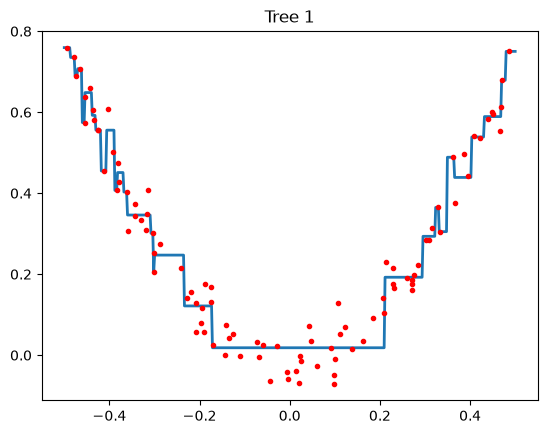

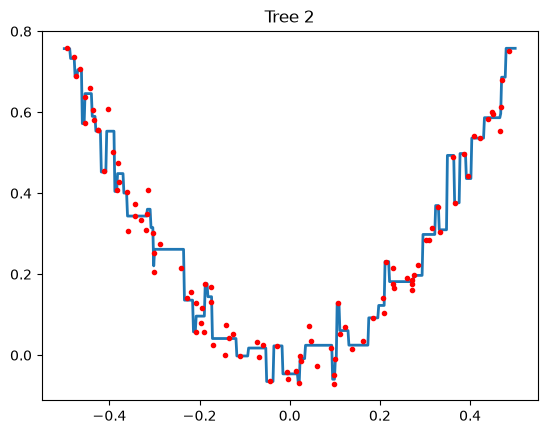

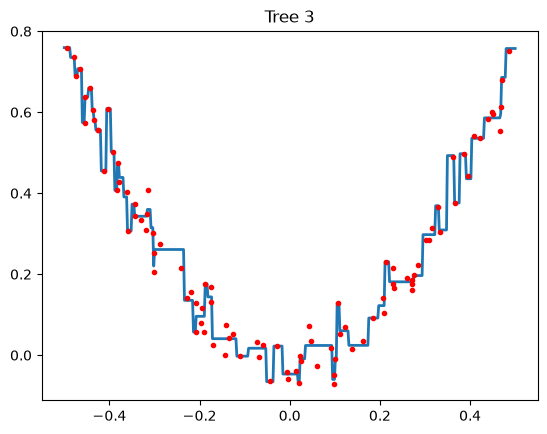

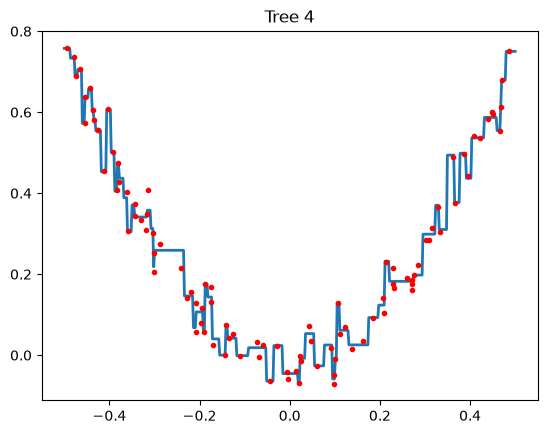

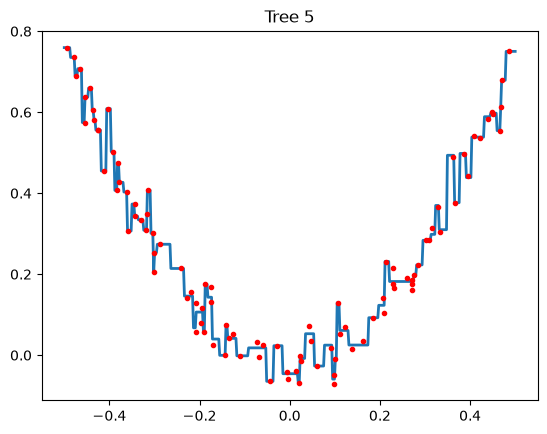

In [71]:
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)
regs = gradient_boost(X, y, 5, lr=1)